In [1]:
import torch
from torch import nn
import numpy as np
import cv2
import matplotlib.pyplot as plt

from sift import SIFTParams, build_octaves, build_dog, find_scale_space_extrema
from util import draw_octaves_grid, assert_octaves, read_octaves

In [2]:
# read the same way as in course to reuse numerical tests

image = cv2.imread("data/mysh1.jpg")

rows, cols = image.shape[:2]
image = cv2.resize(image, (cols // 8, rows // 8), interpolation=cv2.INTER_AREA)
image = cv2.cvtColor(image, cv2.COLOR_BGRA2GRAY)
image = torch.from_numpy(image).to(torch.float32) / 255.0
image = image.unsqueeze(0)

# F.to_pil_image(image)

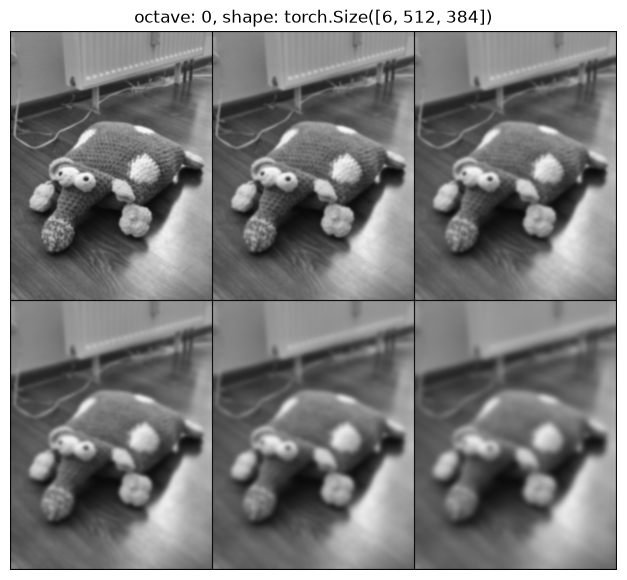

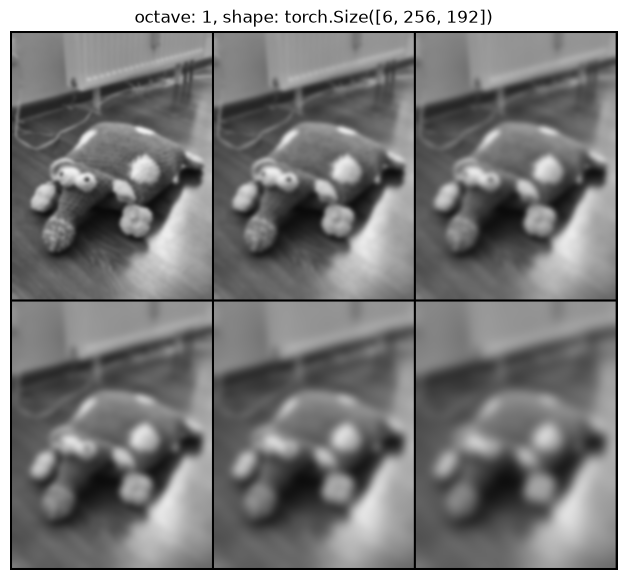

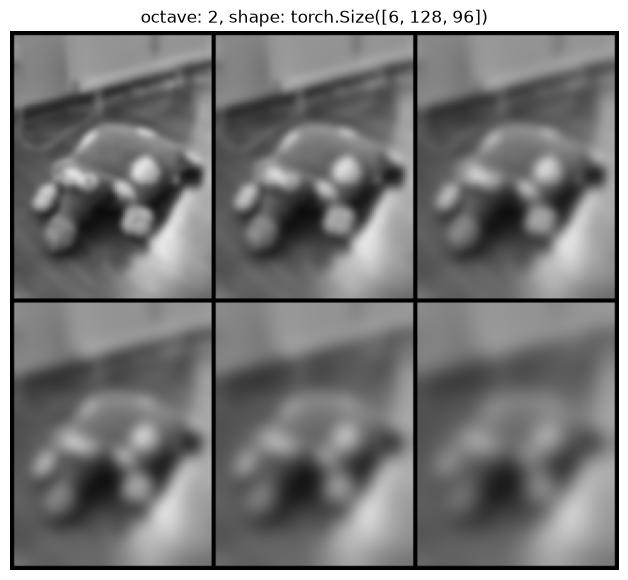

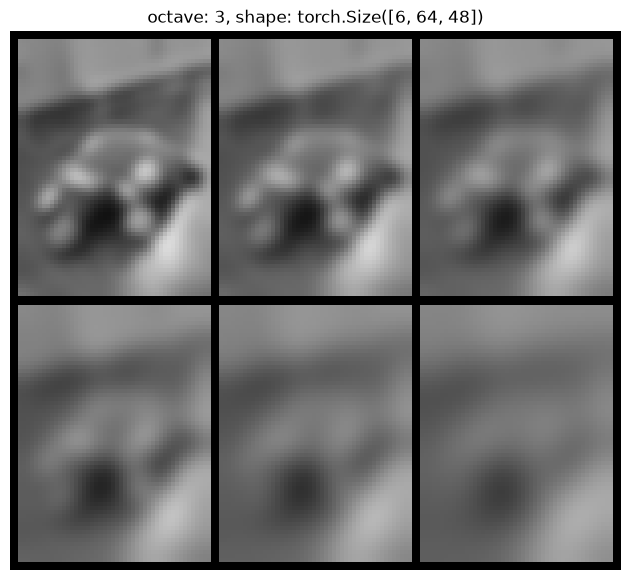

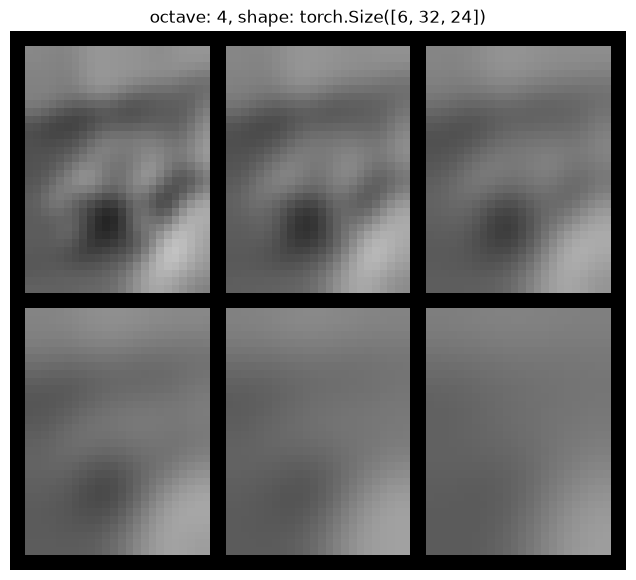

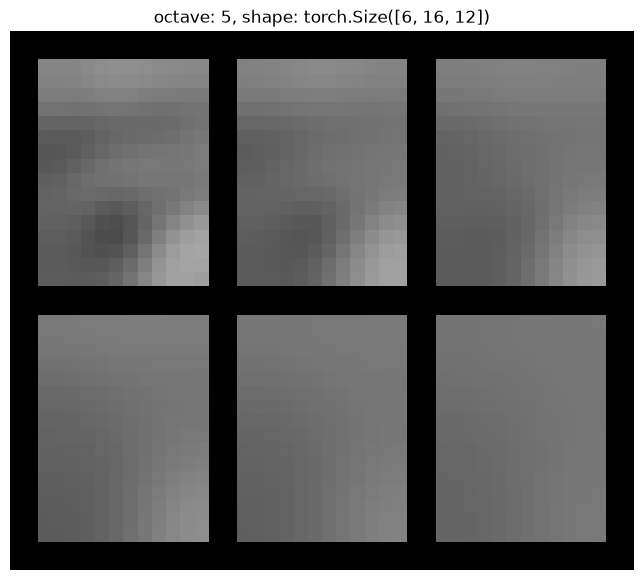

In [3]:
params = SIFTParams()
params.upscale_first = False

octaves = build_octaves(image, params)

draw_octaves_grid(octaves)

In [4]:
ref_octaves = read_octaves('data/test_steps_data/step1_octaves.yml.gz')

assert_octaves(octaves, ref_octaves)

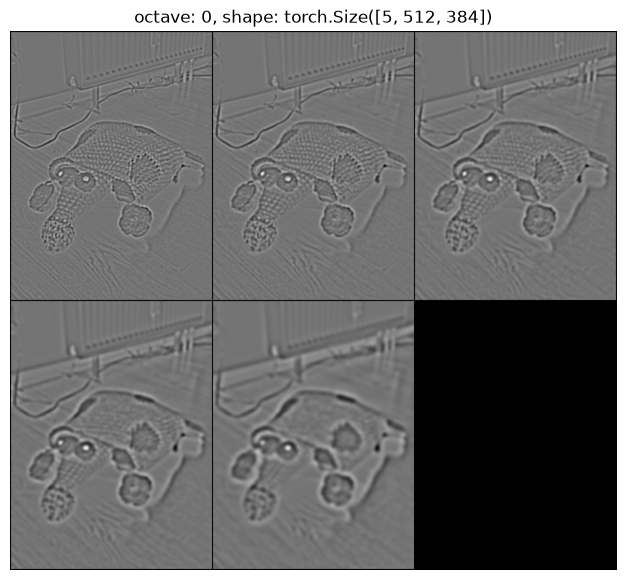

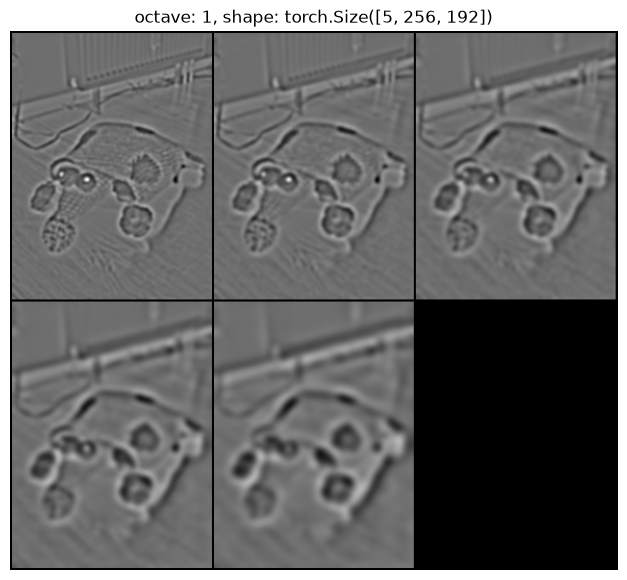

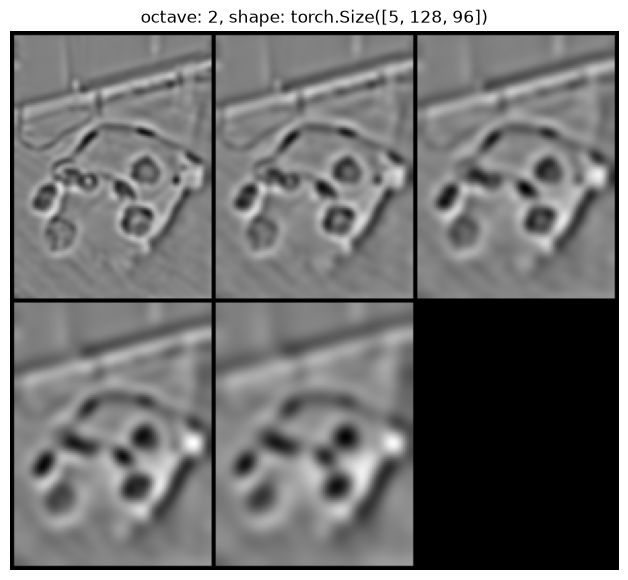

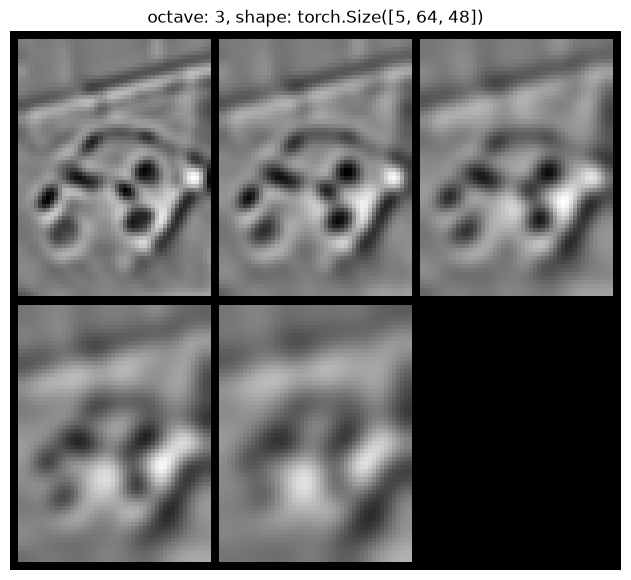

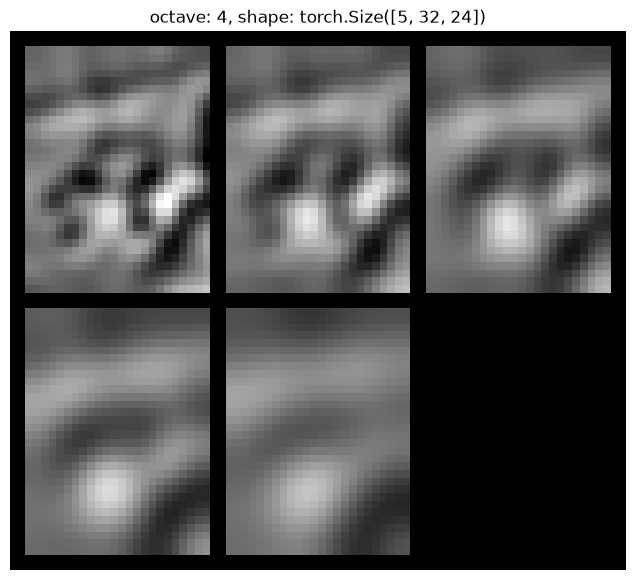

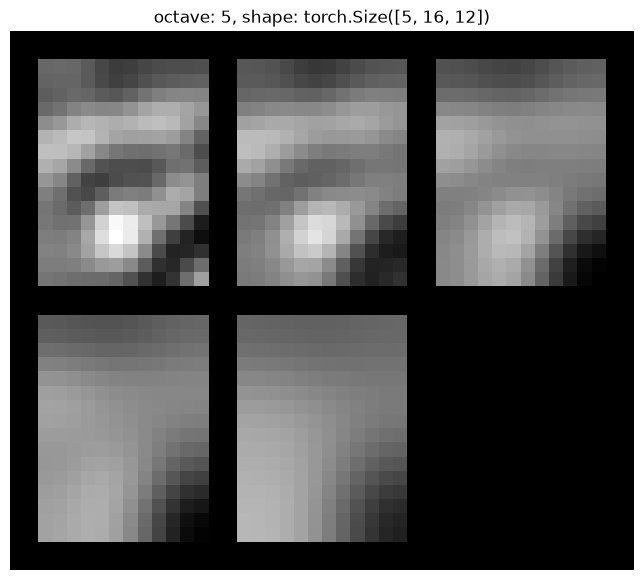

In [5]:
dog = build_dog(octaves)

draw_octaves_grid(dog, normalize=True)

In [6]:
ref_dog = read_octaves("data/test_steps_data/step2_dog.yml.gz")

assert_octaves(dog, ref_dog)

In [7]:
import torch
import torch.nn.functional as F
from sift import build_gradient_kernel, build_hessian_kernel, KeyPoint

s = params.n_octave_layers
sigma0 = params.sigma
contrast_threshold = params.contrast_threshold
edge_threshold = params.edge_threshold
enable_subpixel_localization = params.enable_subpixel_localization

thresh = contrast_threshold / s

first_octave = -1 if params.upscale_first else 0

grad_kernel = build_gradient_kernel(device=dog[0].device)
hessian_kernel = build_hessian_kernel(device=dog[0].device)

keypoints: list[KeyPoint] = []

for i, octave in enumerate(dog):
    real_octave = i + first_octave
    
    # check for threshold
    center = octave[1:-1, 1:-1, 1:-1]
    contrast_mask = center.abs() > thresh * 0.5

    # check for local min/max
    S, rows, cols = octave.shape

    is_max = torch.ones_like(center, dtype=torch.bool)
    is_min = torch.ones_like(center, dtype=torch.bool)

    for ds in (-1, 0, 1):
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if ds == dy == dx == 0:
                    continue

                neighbor = octave[
                    1 + ds : S - 1 + ds,
                    1 + dy : rows - 1 + dy,
                    1 + dx : cols - 1 + dx,
                ]

                is_max &= center > neighbor
                is_min &= center < neighbor
    
    extrema_mask = is_max | is_min

    # solve linear systems (finding local extrema)
    grad = F.conv3d(octave[None, None, ...], weight=grad_kernel)
    hessian = F.conv3d(octave[None, None, ...], weight=hessian_kernel)

    g0 = grad.movedim(1, -1)[0]  # [S, rows, cols, 3]
    H0 = hessian.movedim(1, -1).unflatten(-1, (3, 3))[0]

    S, rows, cols = g0.shape[:3]
    device = g0.device

    ss, yy, xx = torch.meshgrid(
        torch.arange(S, device=device),
        torch.arange(rows, device=device),
        torch.arange(cols, device=device),
        indexing="ij",
    )

    coords = torch.stack([ss, yy, xx], dim=-1).reshape(-1, 3)
    limits = torch.tensor([S, rows, cols], device=device)

    candidate_mask = contrast_mask & extrema_mask

    coords = coords[candidate_mask.reshape(-1)]

    ready_coords = []
    ready_offsets = []

    # 5 attempts to have local offsets less then 0.5
    for _ in range(5):
        if coords.shape[0] == 0:
            break

        si, yi, xi = coords.unbind(dim=-1)

        offset, info = torch.linalg.solve_ex(
            H0[si, yi, xi],
            -g0[si, yi, xi].unsqueeze(-1),
        )
        offset = offset.squeeze(-1)  # [N_active, syx]

        solved = (info == 0) & torch.isfinite(offset).all(dim=-1)
        ready = solved & (offset.abs() < 0.5).all(dim=-1)
        move = solved & ~ready

        ready_coords.append(coords[ready])
        ready_offsets.append(offset[ready])

        coords = coords[move] + offset[move].round().long()

        inside = ((coords >= 0) & (coords < limits)).all(dim=-1)
        coords = coords[inside]

    ready_coords = (
        torch.cat(ready_coords)
        if ready_coords
        else torch.empty((0, 3), dtype=torch.long, device=device)
    ) # [K, syx]

    ready_offsets = (
        torch.cat(ready_offsets)
        if ready_offsets
        else g0.new_empty((0, 3))
    ) # [K, syx]

    # finding floating point response (px response + offset)
    si, yi, xi = ready_coords.unbind(dim=-1)
    g_ready = g0[si, yi, xi]
    center_ready = center[si, yi, xi]

    dot = (ready_offsets * g_ready).sum(dim=-1)
    response_optimized = center_ready + 0.5 * dot
    response_mask = response_optimized.abs() > thresh

    ready_coords = ready_coords[response_mask]
    ready_offsets = ready_offsets[response_mask]
    response_optimized = response_optimized[response_mask]

    # checking for enable_edge_like_filtering
    if params.enable_edge_like_filtering:
        si, yi, xi = ready_coords.unbind(dim=-1)
        H0_ready = H0[si, yi, xi]
        # dxx dxy, dxy, dyy
        dxx = H0_ready[:, 2, 2]
        dxy = H0_ready[:, 1, 2]
        dyy = H0_ready[:, 1, 1]

        trace = dxx + dyy
        det = dxx * dyy - dxy * dxy
        det_mask = det > 0

        ready_coords = ready_coords[det_mask]
        ready_offsets = ready_offsets[det_mask]
        response_optimized = response_optimized[det_mask]
        trace = trace[det_mask]
        det = det[det_mask]

        r = edge_threshold
        edge_mask = (trace * trace / det) <= (r + 1) ** 2 / r

        ready_coords = ready_coords[edge_mask]
        ready_offsets = ready_offsets[edge_mask]
        response_optimized = response_optimized[edge_mask]

    # upscale coords
    scale = 2 ** real_octave
    upscaled_coords = ready_coords.to(ready_offsets.dtype) + 1
    layers = ready_coords[:, 0] + 1

    if enable_subpixel_localization:
        upscaled_coords += ready_offsets

    upscaled_coords[:, 1:] *= scale

    kp_sigma = sigma0 * 2 ** (upscaled_coords[:, 0] / s) * scale

    for coord, response, sigma, layer in zip(
        upscaled_coords, response_optimized, kp_sigma, layers
    ):
        point = KeyPoint(
            x=coord[2].item(),
            y=coord[1].item(),
            size=2.0 * sigma.item(),
            octave=real_octave,
            class_id=int(layer.item()),
            response=response.abs().item()
        )
        keypoints.append(point)

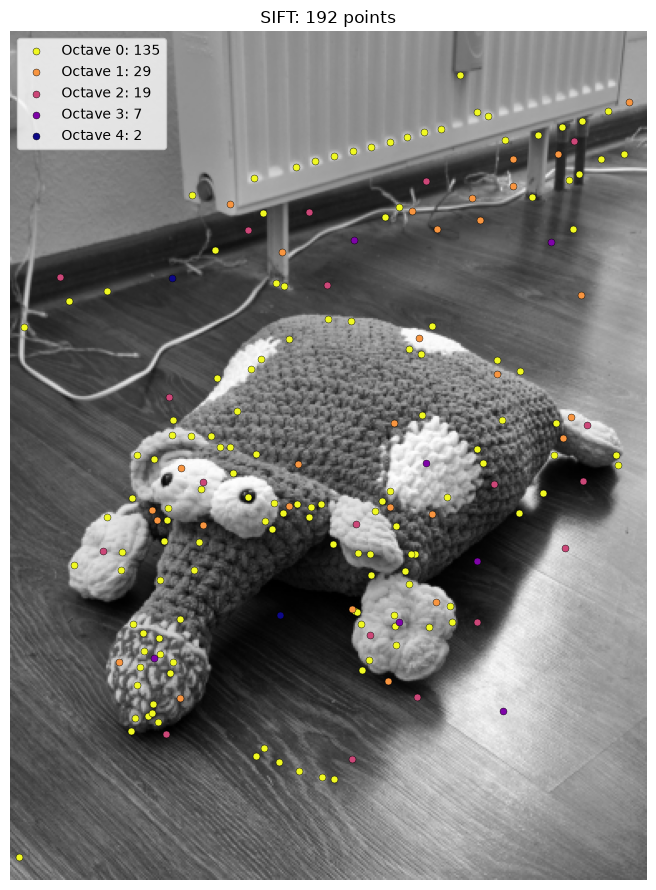

In [8]:
image = image.detach().cpu().numpy() if isinstance(image, torch.Tensor) else image
image = image.squeeze()

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(image, cmap="gray", origin="upper")

octaves = sorted({kp.octave for kp in keypoints})

for i, octave_id in enumerate(octaves):
    points = [kp for kp in keypoints if kp.octave == octave_id]

    color = plt.cm.plasma(1 - i / max(len(octaves) - 1, 1))

    ax.scatter(
        [kp.x for kp in points],
        [kp.y for kp in points],
        s=25,
        color=color,
        edgecolors="black",
        linewidths=0.3,
        label=f"Octave {octave_id}: {len(points)}",
    )

ax.legend()
ax.set_title(f"SIFT: {len(keypoints)} points")
ax.axis("off")
plt.tight_layout()
plt.show()